<a href="https://colab.research.google.com/github/charlottemarieolexy-tech/A05-pca/blob/main/A05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [30]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Charlotte Olexy

**Date:** 10/21/2026

In [31]:
# Your Phase 1 solution to the problem goes here.
# token_freq

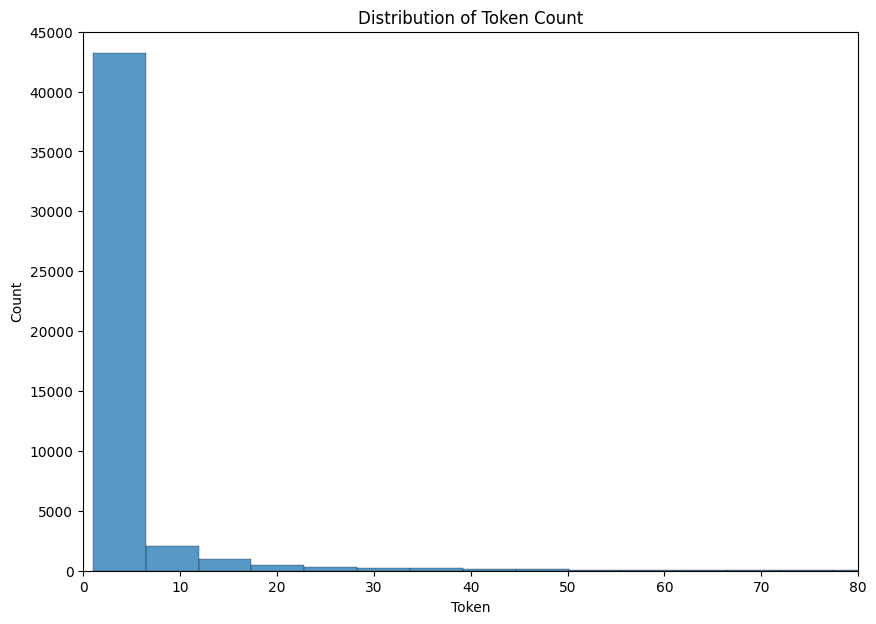

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

tokens = pd.DataFrame(token_freq, columns= ["Token", "Count"])

fig, ax  = plt.subplots(figsize=(10,7))

sns.histplot(
    data=tokens,
    x="Count",
    bins=250,
    ax=ax
)
ax.set_title("Distribution of Token Count")
ax.set_xlabel("Token")
plt.xlim(0,80)
plt.ylim(0, 45000)
plt.show()

#What do you notice about the frequency of occurrence of different tokens? How does it look?

The distribution is extremely skewed to the right. Most of the tokens have a count of 1-3, meaning that the frequency of the occurence of most of the tokens was relatively low. However, there are a few tokens that have a high count ranging from 10 to 65 in relation to the majority.

In [33]:
#Question 2 - Reading in the Phishing clean parquet file

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

emails = pd.read_parquet("Phishing_clean.parquet")
X = emails.drop(columns=["Email Type"])
y = emails["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, train_size=0.80, random_state=42)

regression = LinearRegression().fit(X_train, y_train)
print("R-squared (Train):",r2_score(y_train, regression.predict(X_train)))
print("R-squared (Test):",r2_score(y_test, regression.predict(X_test)), "\n")

coefs = pd.Series(regression.coef_, index=X.columns)

print(coefs.abs().sort_values(ascending=False).head(5))


R-squared (Train): 0.7670143724934355
R-squared (Test): 0.6658718438847919 

intervention         1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:    0.622909
dtype: float64


#What is the  R2  on the test set? On the training set? What words have the largest coefficients in absolute value and most strongly influence predictions?

The R squared differs between the training and test sets, with the training set having a greater R squared of 0.77 (stronger relationship) in comparison to the test set with an R squared of 0.67. The words with the top coefficients appear to be" intervention, localized, thermal, crawler, and background-image.

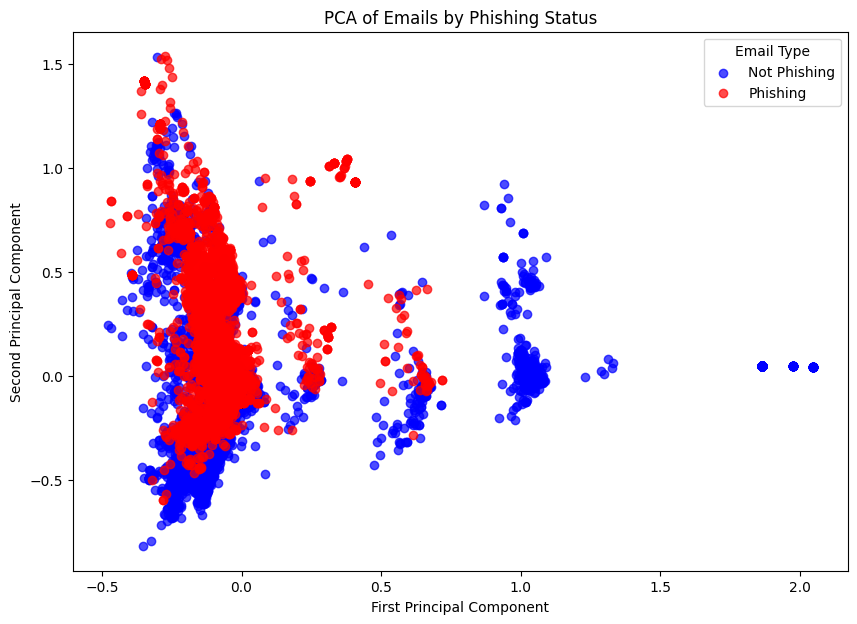

In [34]:
#Q3 - PCA
from sklearn.decomposition import PCA
import numpy as np

emails_pca = PCA(n_components=2).fit(X).transform(X)

fig, ax = plt.subplots(figsize=(10,7))

ax.scatter(
    x=emails_pca[y == 0, 0],
    y=emails_pca[y == 0, 1],
    color = 'blue',
    label = 'Not Phishing',
    alpha = 0.7,
)

ax.scatter(
    x=emails_pca[y == 1, 0],
    y=emails_pca[y == 1, 1],
    color ='red',
    label="Phishing",
    alpha=0.7
)

ax.set_xlabel("First Principal Component")
ax.set_ylabel("Second Principal Component")
ax.set_title("PCA of Emails by Phishing Status")
ax.legend(title='Email Type')

# Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

The PCA plots most of the phishing emails and non-phishing emails over top of each other near the y axis instead of two separate, distinct clusters. While the predictions of Not-Phishing Emails are more spread out, the large overlapping cluster of both Phishing and Non-Phishing emails indicates that the PC analysis with only 2 components does not do a good job of capturing enough of the variance in the data to more accurately predict which emails are scams vs. not.

In [35]:
#Q4 - 2610 Components
pca = PCA(n_components=2610)
emails_pca_2610_train = pca.fit_transform(X_train)
emails_pca_2610_test = pca.transform(X_test)

pca_reg = LinearRegression().fit(emails_pca_2610_train, y_train)

print("Principle Component Regression Train R2:", r2_score(y_train, pca_reg.predict(emails_pca_2610_train)))
print("Principle Component Regression Test R2:", r2_score(y_test, pca_reg.predict(emails_pca_2610_test)))
print("Variance explained by 2610 principle components:", pca.explained_variance_ratio_.sum())


Principle Component Regression Train R2: 0.7662326827745849
Principle Component Regression Test R2: 0.6683390643101164
Variance explained by 2610 principle components: 0.9998620409568273


#How does this performance compare to the linear regression?

The R2 for the PCA training set regression is 0.766 and the test set regression is 0.668. This is very similar to the R2 from the linear regression which was 0.767 for the training set and 0.666. The R2s being very similar in value makes sense because the PCA captures 99.986% of the variance which essentially is almost all of the components that affect the variation in R2 in the linear regression. Since we only dropped 101 of the components with the lowest-variance(from 2,711 to 2610), not much from the data was removed, changing the fit very minimally. Despite this trivial difference, there is still a slight change. Since the R2 of the training set is lowered from 0.767 to 0.766 by dropping some direction and the R2 of the test set is raised from 0.666 to 0.668, dropping a few noisy, low variance components indicates that the PCA did slightly improve the fit.

# Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

The original data is noisy, with thousands of word columns that sometimes overlap, presenting issues of multicollinearity and instability. When we run a regression on the original data, this noisy data makes the model more unstable and prone to overfitting. Principal components, 2610 in this case, help combine these overlapping/highly correlated words to produce a new set of variables that are uncorrelated with one another and ordered by the information they provide about the data's variance so we can drop the lower variance components that may reduce model complexity.
In our case, we only dropped 101 out of 2711 components which is only 3.7% of all the components and why it didn't change the R2 by much. If we were to drop a few more components (but not too many more), the PCA should allow for a more stable, better performing model.  



## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** b905642
- **AI tool and model used:** Chat GPT, powered by OpenAI’s GPT-6 model

### *Prompts used

1. how can i clean up my code for efficiency an/or better data visualizations
2. How to do log transformation on my initial histogram

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

**1.** I looked at your A05 Phase 1.html notebook. Since this is a PCA and text-analysis assignment involving phishing emails, one-hot-encoded word features, regression, and principal component analysis, I would focus on three things: reducing repetitive code, making your visualizations easier to interpret, and making your analysis more statistically sound.

Here is how I would approach improving it while keeping your existing analysis and assignment requirements intact.
1. The biggest improvements I would make:


1. Reduce repetitive code

Create reusable functions for repeated plotting, model evaluation, and displaying results. This makes your notebook shorter and easier to maintain.

2. Improve the visualizations

Replace hard-to-read plots with clearly labeled charts, sorted horizontal bar charts, and more informative PCA scatterplots.

3. Make the analysis more efficient and reliable

Avoid fitting the same models multiple times, use consistent train/test splits, and fit PCA only on training data when evaluating predictive performance.


2. Clean up your code with reusable functions
A. Simplify your regression evaluation
Your notebook evaluates training and test \(R^2\) and examines the largest regression coefficients. You can combine those steps into a reusable function rather than rewriting the same code for every model.

from sklearn.metrics import r2_score

import pandas as pd

def evaluate_model(model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)    
    scores = pd.Series({        "Training R²": r2_score(            y_train, model.predict(X_train)        ),        "Test R²": r2_score(            y_test, model.predict(X_test)        )    })    
    return model, scores



Use it for your original regression:

from sklearn.linear_model import LinearRegression

regression, scores = evaluate_model(    LinearRegression(),    
X_train, X_test, y_train, y_test)

display(scores.round(3))

You can reuse the same function for your PCA regression, provided you pass the corresponding transformed training and test data.

Why this is better: it reduces repeated code, keeps the evaluation method consistent, and makes it easier to compare models.
B. Display the largest regression coefficients more clearly
Your existing approach sorts the absolute values of the coefficients to identify the most influential tokens. That's a good start, but a horizontal bar chart can make the results much easier to interpret.

import matplotlib.pyplot as plt

coefs = pd.Series(regression.coef_, index=X_train.columns)

top_coefs = coefs.loc[    coefs.abs().nlargest(10).index].sort_values()

plt.figure(figsize=(9, 6))

top_coefs.plot(kind="barh")

plt.axvline(0, color="black", linewidth=0.8)

plt.xlabel("Regression coefficient")

plt.ylabel("Email token")

plt.title("10 Tokens With the Largest Absolute Coefficients")

plt.tight_layout()

plt.show()

This version uses the signed coefficients, rather than only displaying their absolute values.
- Positive coefficients increase the model's predicted probability of a phishing email.
- Negative coefficients decrease the predicted probability.
- Larger absolute coefficients indicate stronger associations in this fitted model, holding the other features constant.
Because the outcome is binary, these are coefficients from a linear probability model, not logistic-regression log-odds. Also, coefficients alone do not establish causation.

3. Improve your data visualizations
Here are the changes I would prioritize for your particular assignment.

A. Token frequency distribution

Your written interpretation describes a strongly right-skewed distribution, with many low-frequency tokens and a few much more common ones.
- Use a histogram with clearly labeled axes.
- Consider a logarithmic x-axis or y-axis if the distribution is very skewed.
- Alternatively, plot the 15–20 most frequent tokens as a sorted bar chart.
A bar chart of the most frequent tokens is often more interpretable than a histogram alone because you can see which tokens drive the distribution.

B. PCA scatterplot

Your assignment requires plotting the first two principal components, colored by phishing status.
- Label axes as PC1 and PC2, ideally with the percentage of variance explained.
- Use a clear legend such as Legitimate and Phishing.
- Add transparency to overlapping points with alpha=0.5.
- Use a consistent figure size and avoid oversized markers.
This makes it easier to judge whether the two email classes form distinct clusters or overlap substantially.

C. Compare the two regressions

Your notebook reports very similar training and test (R^2\) values for the original features and the PCA features.

A grouped bar chart comparing the two models' training and test scores would make the similarity immediately visible. A small table is also a good option if you prefer a simpler presentation.

Example: Improve your PCA scatterplot
Assuming you already have your two-component PCA results stored in X_pca and the corresponding outcomes in y, you can use:

import matplotlib.pyplot as plt

import seaborn as sns

import pandas as pd

pca_plot = pd.DataFrame({    "PC1": X_pca[:, 0],    "PC2": X_pca[:, 1],    "Email Type": y})

pca_plot["Email Type"] = pca_plot["Email Type"].map({    0: "Legitimate",    1: "Phishing"})

plt.figure(figsize=(9, 6))

sns.scatterplot(    data=pca_plot,    x="PC1",    y="PC2",    hue="Email Type",    alpha=0.6,    s=35)

plt.title("PCA of Email Token Features")

plt.xlabel("First Principal Component")

plt.ylabel("Second Principal Component")

plt.legend(title="Email Classification")

plt.tight_layout()

plt.show()

If your current PCA object is named differently, substitute the appropriate variable. This example assumes the rows in X_pca and y are in the same order.

4. One important statistical improvement: avoid data leakage
Your assignment compares the predictive performance of the original token features against a regression using 2,610 principal components. If you want to make that comparison rigorous, the PCA transformation should be learned using only the training set.

For example:

from sklearn.decomposition import PCA

pca = PCA(n_components=2610)

X_train_pca = pca.fit_transform(X_train)

X_test_pca = pca.transform(X_test)

Then fit the regression on X_train_pca and evaluate it on X_test_pca.

The distinction is important: fit_transform() learns the PCA directions, while transform() applies those same directions to new data. Fitting PCA on the full dataset before splitting allows information from the test features to influence the transformation.

One caveat: PCA on thousands of token features can be computationally expensive, so it is worth reusing the fitted transformation instead of recalculating it unnecessarily.

5. Make the notebook easier to follow
I would organize your notebook into a consistent sequence:
1. Imports and setup — import libraries once.
2. Data loading and cleaning — load the email data and inspect its structure.
3. Exploratory data analysis — token frequency distribution and descriptive observations.
4. Baseline regression — split the data, fit the model, evaluate \(R^2\), and visualize coefficients.
5. PCA analysis — transform features and plot the first two components.
6. PCA regression — compare training and test performance against the baseline.
7. Conclusions — explain what the visualizations and model comparisons show.
Use descriptive variable names, avoid repeating imports, and keep each code cell focused on one task. You don't need to turn every few lines into a function; reusable functions are most valuable when the same operation is performed multiple times.

One assignment-specific consideration: your exported notebook says to keep Phase 1 frozen and complete the AI-assisted revision in Phase 2. Make these changes in Phase 2 rather than altering your original Phase 1 work.

What I would prioritize first
If you only have time for three changes, I would:
- Replace the coefficient output with the signed horizontal bar chart.
- Improve the PCA scatterplot's labels, legend, and transparency.
- Create one model-evaluation function and use it for both regressions.
Those changes give you a cleaner notebook and more interpretable results without unnecessarily complicating the code.

I can also go through the notebook cell by cell and suggest specific replacements for your existing code, including your token-frequency plot, PCA visualization, and regression sections.

**2.** Since your initial histogram of token occurrences is highly right-skewed, a log transformation can help make the distribution easier to interpret by compressing very large counts and spreading out smaller values.

There are two ways to do this, depending on what you want to show.
Option 1: Use a log scale on the y-axis (recommended)
This keeps your original token counts unchanged and makes it easier to see the distribution of less frequent tokens.

import matplotlib.pyplot as plt

import seaborn as sns

plt.figure(figsize=(10, 6))

sns.histplot(data=token_counts, bins=30)

plt.yscale("log")

plt.title("Distribution of Token Occurrences")

plt.xlabel("Number of Occurrences")

plt.ylabel("Number of Tokens (Log Scale)")

plt.tight_layout()

plt.show()

Important: This assumes token_counts is a Series or array containing the occurrence count for each token. If your variable has a different name, replace token_counts with that variable.

Option 2: Log-transform the token counts themselves
If you want to transform the actual values on the x-axis, use np.log1p(). This calculates \(\log(1+x)\), allowing you to handle tokens with zero occurrences without taking the logarithm of zero.

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

log_counts = np.log1p(token_counts)

plt.figure(figsize=(10, 6))

sns.histplot(log_counts, bins=30)

plt.title("Distribution of Log-Transformed Token Occurrences")

plt.xlabel("Log(1 + Number of Occurrences)")

plt.ylabel("Number of Tokens")

plt.tight_layout()

plt.show()

Which should you use?
- Option 1: Best if you want to preserve the original count values while making the histogram's smaller bars more visible.
- Option 2: Best if you specifically want to transform the distribution of token counts to reduce skewness.
For your assignment, I would start with Option 1 because it preserves the original units of token occurrences and makes the histogram easier to read. Note that a log-scaled y-axis changes the display of the number of tokens per bin, not the skewness of the token counts themselves.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | **Accept** / modify / reject | I kept the function and the modified way to grpah the scatterplot because it was a more efficient code. To verify, I compared the R2 outputs from my Phase 1 code to the AI generated code's R2 outputs. |
| 2 | Accept / **modify** / reject | I used only part of the code just to edit mine for the log transformation, rather than replace my code entirely. I verified it by comparing my new graph to my old one and made sure no errors occurred when I ran the code. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

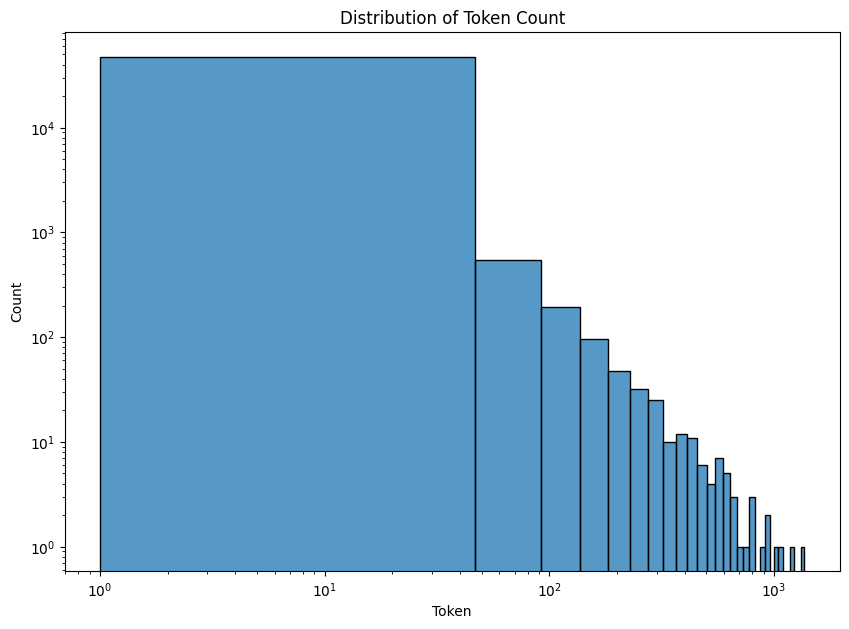

In [36]:
# Your Phase 2 solution to the problem goes here.
fig, ax  = plt.subplots(figsize=(10,7))

sns.histplot(
    data=tokens,
    x="Count",
    bins=30,
    ax=ax
)

ax.set_title("Distribution of Token Count")
ax.set_xlabel("Token")
plt.yscale("log")
plt.xscale("log")
plt.show()

#What do you notice about the frequency of occurrence of different tokens? How does it look?

The distribution is extremely skewed to the right. Most of the tokens have a count of 1-3, meaning that the frequency of the occurence of most of the tokens was relatively low. However, there are a few tokens that have a high count ranging from 10 to 65 in relation to the majority.

In [37]:
# Q2 - Splitting the data
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

emails = pd.read_parquet("Phishing_clean.parquet")
X = emails.drop(columns=["Email Type"])
y = emails["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, train_size=0.80, random_state=42)

In [38]:
#Q2 - Finding Linear Regression R2
def evaluate_model(model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)

    scores = pd.Series({
        "Training R²": r2_score(
            y_train, model.predict(X_train)
        ),
        "Test R²": r2_score(
            y_test, model.predict(X_test)
        )
    })

    return model, scores

regression, scores = evaluate_model(
    LinearRegression(),
    X_train, X_test, y_train, y_test
)

display(scores.round(3))

,0
Training R²,0.767
Test R²,0.666


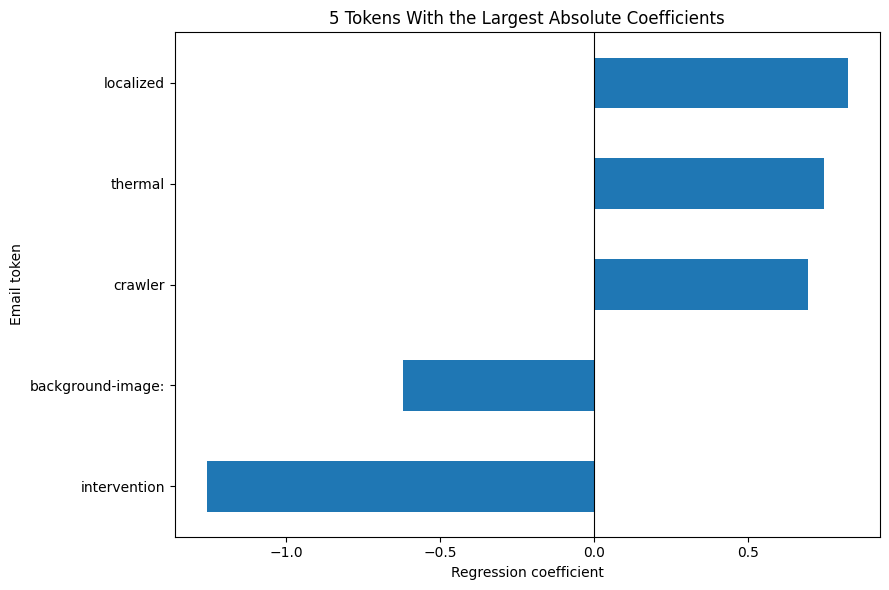

In [42]:
#Q2 - Finding Coefficients with Largest Coefficients
top_coefs = coefs.loc[
    coefs.abs().nlargest(5).index
].sort_values()

plt.figure(figsize=(9, 6))
top_coefs.plot(kind="barh")

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Regression coefficient")
plt.ylabel("Email token")
plt.title("5 Tokens With the Largest Absolute Coefficients")
plt.tight_layout()
plt.show()

#What is the  R2  on the test set? On the training set? What words have the largest coefficients in absolute value and most strongly influence predictions?

The R squared differs between the training and test sets, with the training set having a greater R squared of 0.77 (stronger relationship) in comparison to the test set with an R squared of 0.67. The words with the top coefficients appear to be" intervention, localized, thermal, crawler, and background-image.

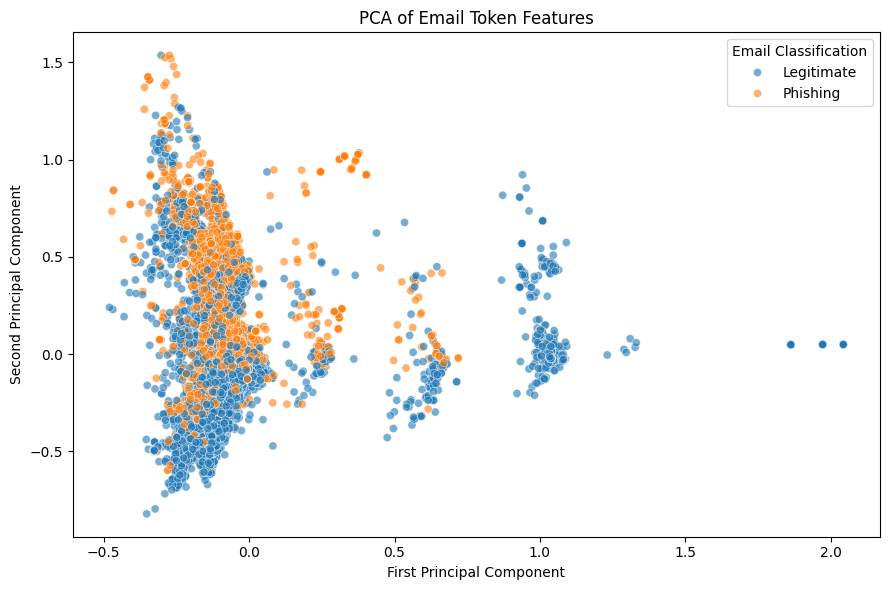

In [40]:
#Q3 - Plotting 2 Component PCA Scatterplot
emails_pca = PCA(n_components=2).fit(X).transform(X)

pca_plot = pd.DataFrame({
    "PC1": emails_pca[:, 0],
    "PC2": emails_pca[:, 1],
    "Email Type": y
})

pca_plot["Email Type"] = pca_plot["Email Type"].map({
    0: "Legitimate",
    1: "Phishing"
})

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_plot,
    x="PC1",
    y="PC2",
    hue="Email Type",
    alpha=0.6,
    s=35
)

plt.title("PCA of Email Token Features")
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.legend(title="Email Classification")
plt.tight_layout()
plt.show()

# Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

The PCA plots most of the phishing emails and non-phishing emails over top of each other near the y axis instead of two separate, distinct clusters. While the predictions of Not-Phishing Emails are more spread out, the large overlapping cluster of both Phishing and Non-Phishing emails indicates that the PC analysis with only 2 components does not do a good job of capturing enough of the variance in the data to more accurately predict which emails are scams vs. not.

In [41]:
#Q4 - 2610 Components Regression and R2
pca = PCA(n_components=2610)
emails_pca_2610_train = pca.fit_transform(X_train)
emails_pca_2610_test = pca.transform(X_test)

regression, scores = evaluate_model(
    LinearRegression(),
    emails_pca_2610_train, emails_pca_2610_test, y_train, y_test
)

display(scores.round(3))

print("\nVariance explained by 2610 principle components:", pca.explained_variance_ratio_.sum())

,0
Training R²,0.766
Test R²,0.668



Variance explained by 2610 principle components: 0.9998620409568273


#How does this performance compare to the linear regression?

The R2 for the PCA training set regression is 0.766 and the test set regression is 0.668. This is very similar to the R2 from the linear regression which was 0.767 for the training set and 0.666. The R2s being very similar in value makes sense because the PCA captures 99.986% of the variance which essentially is almost all of the components that affect the variation in R2 in the linear regression. Since we only dropped 101 of the components with the lowest-variance(from 2,711 to 2610), not much from the data was removed, changing the fit very minimally. Despite this trivial difference, there is still a slight change. Since the R2 of the training set is lowered from 0.767 to 0.766 by dropping some direction and the R2 of the test set is raised from 0.666 to 0.668, dropping a few noisy, low variance components indicates that the PCA did slightly improve the fit.

# Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

The original data is noisy, with thousands of word columns that sometimes overlap, presenting issues of multicollinearity and instability. When we run a regression on the original data, this noisy data makes the model more unstable and prone to overfitting. Principal components, 2610 in this case, help combine these overlapping/highly correlated words to produce a new set of variables that are uncorrelated with one another and ordered by the information they provide about the data's variance so we can drop the lower variance components that may reduce model complexity.
In our case, we only dropped 101 out of 2711 components which is only 3.7% of all the components and why it didn't change the R2 by much. If we were to drop a few more components (but not too many more), the PCA should allow for a more stable, better performing model.  

### *Reflection on AI assistance
In your own words without generative AI.

I prompted the generative AI to give me suggestions on how to make my code more efficient and the graphical visualizations clearer. The two most insightful suggestions it gave me was to log scale my histogram of the token counts and to define a function to conduct a linear regression with given training and test inputs and return the R2 scores. The log scale allows me to more clearly see the difference in token count frequency since the original graph was skewed extremely to the right. The function allows me to avoid repetitive code that I had originally used in both questions 2 and 4 when running the regressions and finding the R2. The AI model also recommended a different code to plot my scatterplot of the 2 PCs and a visual representation of the words with the largest coefficients. I chose to both implement the entire recommended code or parts of it to edit my own from Phase 1 because they cut down the redundant pieces I originally incorporated and/or plotted new insights more clearly. I verified the code in a few ways. The first was by running the code to see if any runtime errors occurred. When nothing was flagged, I then compared my Phase 1 R2, coefficient, and graphical outputs to the ones produced with the AI code. Through comparison, I assessed that the same outputs were produced and that the code functioned.